# Trabajo Práctico Integrador - Introducción al Análisis de datos
## Entrega 3: Visualizacion de Datos.


## Caso: análisis y predicción de cancelaciones en reservas hoteleras.

## 1. Datos de identificación

- **Apellido y nombre:** Rodriguez Joaquin - Pichulman Miguel
- **Comisión:** 12
- **Dataset asignado:** L
- **Entrega:** 3
- **Fecha:** 13 / 9 / 2026

# 2. Preparación del dataset


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

from sklearn.preprocessing import KBinsDiscretizer, LabelEncoder, OneHotEncoder, MinMaxScaler, StandardScaler

pd.set_option("display.max_columns", None)

In [ ]:
# Carga desde GitHub el dataset original
url = "https://raw.githubusercontent.com/MiguelPichulman/cuartoCuatrimestre/main/analisisDatos/integrador/hotel%20booking%20TPI%20grupo%20L.csv"

# Cargar dataset
df_reservas = pd.read_csv(url)

# Verificar carga
df_reservas.head()

,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,HB-050638,City Hotel,1,302,2024,May,18,5,2024-05-05,0,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,1.0,NaN,0,Transient,62.0,0,0
1,HB-042358,City Hotel,1,65,2023,September,36,5,2023-09-05,1,1,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,1.0,NaN,0,Transient,62.0,0,0
2,HB-113042,City Hotel,0,32,2025,May,22,30,2025-05-30,0,2,2,0.0,0,SC,ISR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,160.0,0,2
3,HB-020264,Resort Hotel,0,3,2024,February,8,25,2024-02-25,0,1,1,0.0,0,BB,PRT,Online TA,TA/TO,1,0,1,A,D,0,No Deposit,240.0,NaN,0,Transient,43.0,1,2
4,HB-017627,Resort Hotel,0,5,2023,October,41,10,2023-10-10,2,6,2,0.0,0,BB,NLD,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,36.0,NaN,0,Transient,42.0,0,0


# 3. Copia de trabajo

In [ ]:
df_reservas_copia = df_reservas.copy()

#4. Diagnostico

In [ ]:
print(df_reservas_copia.shape)

(25000, 32)


In [ ]:
df_reservas_copia.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   booking_id                      25000 non-null  object 
 1   hotel                           25000 non-null  object 
 2   is_canceled                     25000 non-null  int64  
 3   lead_time                       25000 non-null  int64  
 4   arrival_date_year               25000 non-null  int64  
 5   arrival_date_month              25000 non-null  object 
 6   arrival_date_week_number        25000 non-null  int64  
 7   arrival_date_day_of_month       25000 non-null  int64  
 8   arrival_date                    25000 non-null  object 
 9   stays_in_weekend_nights         25000 non-null  int64  
 10  stays_in_week_nights            25000 non-null  int64  
 11  adults                          25000 non-null  int64  
 12  children                        

In [ ]:
df_reservas_copia.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,24999.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,21578.000000,1385.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,0.367280,104.103800,2024.159680,26.653120,15.757160,0.934920,2.514200,1.854520,0.104524,0.007800,0.030640,0.085280,0.125720,0.222080,87.076096,185.955235,2.301840,102.401390,0.063400,0.564400
std,0.482073,106.570826,0.706458,13.340036,8.797086,1.005905,1.934577,0.513737,0.398708,0.089775,0.172344,0.852782,1.500828,0.650336,110.940284,130.025751,17.457866,58.333739,0.244505,0.786764
min,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2024.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,70.000000,0.000000,0.000000
50%,0.000000,70.000000,2024.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,174.000000,0.000000,95.000000,0.000000,0.000000
75%,1.000000,161.000000,2025.000000,37.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,255.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2025.000000,52.000000,31.000000,16.000000,40.000000,20.000000,3.000000,2.000000,1.000000,26.000000,70.000000,21.000000,531.000000,543.000000,391.000000,5400.000000,2.000000,5.000000


In [ ]:
df_reservas_copia.describe(include=['object','category'])

,booking_id,hotel,arrival_date_month,arrival_date,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type
count,25000,25000,25000,25000,25000,24911,25000,25000,25000,25000,25000,25000
unique,25000,2,12,793,5,126,7,5,10,11,3,4
top,HB-046974,City Hotel,August,2023-12-05,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient
freq,1,16672,3025,83,19243,10088,11917,20483,18091,15626,21948,18806


* Visualización de datos




Construír tres visualizaciones

## 1. Cancelaciones según tipo de hotel. Construí una visualización que permita comparar reservas canceladas y no canceladas entre los distintos tipos de hotel. Podés reutilizar y mejorar el gráfico elaborado en la Práctica 1.

## 2. Variable cuantitativa y cancelación. Elegí una variable cuantitativa relevante, por ejemplo lead_time, adr o la duración total de la estadía, y construí una visualización que permita analizar su comportamiento en relación con is_canceled.

## 3. Una pregunta propia de análisis. Elegí otra relación que consideres relevante para comprender el problema de cancelación. Podés trabajar con variables categóricas, temporales o incorporar más de una dimensión mediante color, agrupamiento o facetas.

 Para cada visualización incluí:

la pregunta de análisis que intentás responder;
una breve explicación de por qué seleccionaste ese tipo de gráfico;
título, ejes y leyenda claramente identificados cuando corresponda;
una interpretación breve de los principales patrones, diferencias o relaciones observadas.

Cierre del notebook

Finalizá con una síntesis breve en la que identifiques tres hallazgos obtenidos a partir de las visualizaciones y al menos una limitación o precaución que deba considerarse antes de elaborar conclusiones más amplias.


# Visualización de datos


 Cancelaciones según tipo de hotel
* **Pregunta de análisis:** ¿Cómo se distribuyen las reservas canceladas y no canceladas en función del tipo de hotel (City Hotel vs. Resort Hotel)?
* **Selección del gráfico:** Se seleccionó un gráfico de barras puesto que son los más efectivos para comunicar y comparar frecuencias entre variables cualitativas y categóricas.

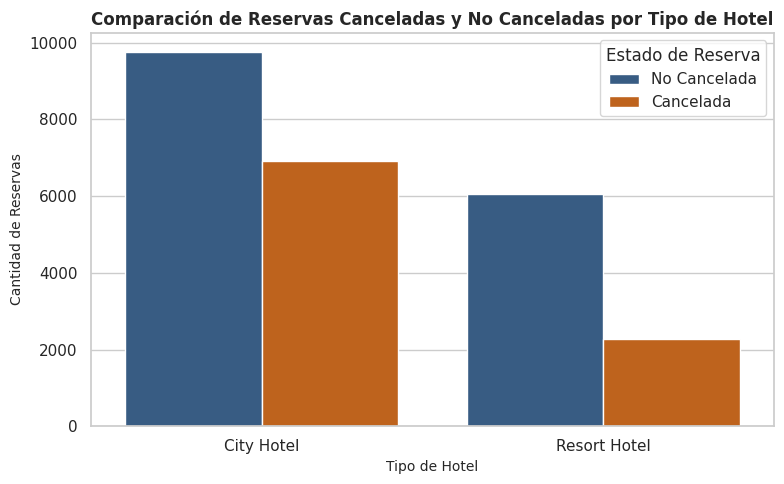

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=df_reservas_copia,
    x='hotel',
    hue='is_canceled',
    palette=['#2b5c8f', '#d95f02'],
    ax=ax,
)
ax.set_title(
    'Comparación de Reservas Canceladas y No Canceladas por Tipo de Hotel',
    fontsize=12,
    weight='bold',
)
ax.set_xlabel('Tipo de Hotel', fontsize=10)
ax.set_ylabel('Cantidad de Reservas', fontsize=10)
ax.legend(title='Estado de Reserva', labels=['No Cancelada', 'Cancelada'])
plt.tight_layout()
plt.show()

El análisis sobre las 25.000 observaciones muestra que el City Hotel concentra 16.672 reservas con una tasa de cancelación del 41.41% (6.904 cancelaciones), mientras que el Resort Hotel registra 8.328 reservas con una tasa de cancelación del 27.35% (2.278 cancelaciones). Esto demuestra que los hoteles urbanos enfrentan una mayor inestabilidad en la confirmación final de sus huéspedes.

Selección del gráfico: Se seleccionó un gráfico de barras puesto que son los más efectivos para comunicar y comparar frecuencias entre variables cualitativas y categóricas, permitiendo visualizar de forma clara tanto los valores absolutos como las diferencias entre grupos.

# 2. Variable cuantitativa (lead_time) y cancelación

Pregunta de análisis: ¿La antelación con la que se hace la reserva (lead_time) influye en la probabilidad de que termine cancelándose?

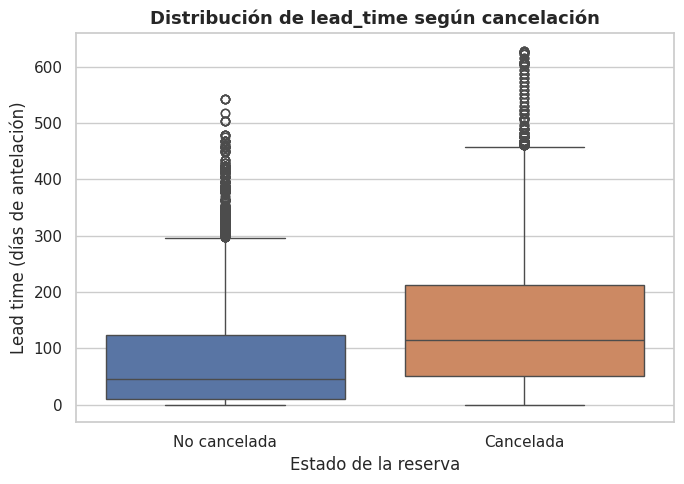

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
sns.boxplot(data=df_reservas_copia, x='is_canceled', y='lead_time', hue='is_canceled',
            palette=['#4C72B0','#DD8452'], legend=False, ax=ax)
ax.set_title('Distribución de lead_time según cancelación', fontsize=13, fontweight='bold')
ax.set_xlabel('Estado de la reserva')
ax.set_ylabel('Lead time (días de antelación)')
ax.set_xticks([0,1])
ax.set_xticklabels(['No cancelada','Cancelada'])
plt.tight_layout()
plt.show()

Las reservas canceladas tienen una mediana de lead_time notablemente más alta (aprox. 115 días) que las no canceladas (aprox. 46 días), y su caja (rango intercuartílico) está desplazada hacia arriba. Es decir, a mayor anticipación con la que se reserva, mayor es la probabilidad de cancelación — tiene sentido intuitivamente: cuanto más lejana está la fecha de viaje, más tiempo hay para que surjan imprevistos que lleven a cancelar.

Por qué este gráfico: un diagrama de cajas es ideal para comparar la distribución completa (mediana, dispersión, outliers) de una variable cuantitativa entre dos grupos categóricos — más informativo que solo comparar promedios, porque además expone la mayor dispersión y los valores atípicos de cada grupo.

# 3. Pregunta propia: tipo de depósito y cancelación

Pregunta de análisis: ¿El tipo de depósito exigido en la reserva (deposit_type) está relacionado con la probabilidad de cancelación?

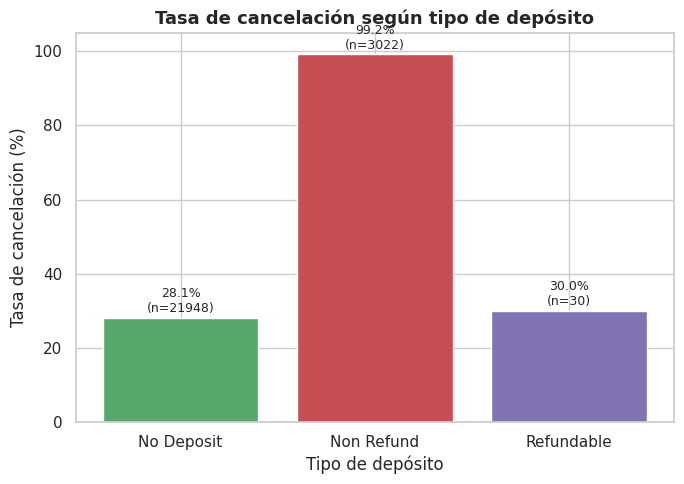

In [ ]:
tasa = df_reservas_copia.groupby('deposit_type')['is_canceled'].mean().reset_index()
conteo = df_reservas.groupby('deposit_type').size().reset_index(name='n')
tasa = tasa.merge(conteo, on='deposit_type')

fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(tasa['deposit_type'], tasa['is_canceled']*100, color=['#55A868','#C44E52','#8172B2'])
ax.set_title('Tasa de cancelación según tipo de depósito', fontsize=13, fontweight='bold')
ax.set_xlabel('Tipo de depósito')
ax.set_ylabel('Tasa de cancelación (%)')
ax.set_ylim(0,105)
for bar, n in zip(bars, tasa['n']):
    h = bar.get_height()
    ax.annotate(f'{h:.1f}%\n(n={n})', xy=(bar.get_x()+bar.get_width()/2, h),
                xytext=(0,4), textcoords='offset points', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

Interpretación: el patrón es el más llamativo de los tres: las reservas con depósito "Non Refund" se cancelan en el 99.2% de los casos, muy por encima de "No Deposit" (28.1%) y "Refundable" (30.0%). Es contraintuitivo — uno esperaría que un depósito no reembolsable desaliente la cancelación — y sugiere que ese segmento de reservas responde a un patrón particular (posiblemente reservas grupales o de agencias con lógicas de cancelación distintas al huésped individual), más que a que el depósito en sí "cause" la cancelación. Vale la pena aclarar esto en el informe para no leer una relación causal donde solo hay una asociación fuerte.

Por qué este gráfico: elegí una barra de tasas (porcentaje) en vez de conteos absolutos porque las tres categorías tienen tamaños muy distintos (No Deposit con 21.876 reservas vs Non Refund con solo 3.021) — comparar porcentajes evita que la categoría más numerosa distorsione la lectura visual, y anoté el n de cada barra para que quede clara esa diferencia de tamaño muestral.

Síntesis y conclusiones

A partir del análisis exploratorio y las visualizaciones realizadas, se identifican tres hallazgos principales:

El tipo de hotel está asociado a la tasa de cancelación. Las reservas de City Hotel se cancelan con mayor frecuencia (41.4%) que las de Resort Hotel (27.4%), lo que sugiere que el contexto del hotel (urbano vs. vacacional) condiciona el comportamiento de cancelación, probablemente por perfiles de huésped o canales de venta distintos entre ambos.
La antelación de la reserva (lead_time) se relaciona con la probabilidad de cancelación. Las reservas canceladas presentan una mediana de antelación considerablemente mayor (~115 días) que las no canceladas (~46 días). Esto es consistente con la idea de que a mayor distancia temporal entre la reserva y la estadía, mayor es la ventana de tiempo para que surjan imprevistos que deriven en una cancelación.
El tipo de depósito exhibe la asociación más fuerte de las tres analizadas. Las reservas con depósito "Non Refund" se cancelan en el 99.2% de los casos, muy por encima de "No Deposit" (28.1%) y "Refundable" (30.0%) — un patrón contraintuitivo que amerita mayor investigación antes de sacar conclusiones definitivas.

Limitaciones y precauciones a considerar:

Asociación no implica causalidad. El hallazgo sobre deposit_type es el ejemplo más claro: que "Non Refund" concentre casi todas sus reservas canceladas no significa que ese tipo de depósito cause la cancelación. Es más probable que esta categoría esté actuando como proxy de otro factor no observado directamente en el dataset (por ejemplo, el tipo de canal de venta o el perfil de quien reserva — reservas grupales o de agencias con lógicas distintas a la del huésped individual). Además, esa categoría representa solo el 12% del dataset (3.021 de 24.927 registros), por lo que hay que ser cautos al generalizar a partir de un subgrupo relativamente pequeño.